## Imports

In [1]:
import os
import matplotlib.pyplot as plt
import awkward as ak
import scienceplots
import numpy as np
from GeoModelSplitCal_Extraction_Classes import SimFileReader, ProcessHits, MIP_Calibration, ECAL_Resolution

## Testing SimFileReader Class

In [2]:
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/"

def main_exec():
    file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_MIP_Calibration/sim_mu-_10000MeV_1000mm.root"
    Sim = SimFileReader(os.path.join(file_path))

    branches = ["edep", "x_global", "y_global", "z_global", "x_local", "y_local", "z_local", "type"]
    edeps, x_globals, y_globals, z_globals, x_local, y_local, z_local, types = Sim.get_branches(branches)
    # print(f"Branches extracted: {branches}")
    # print(f"Number of events: {len(edeps)}")
    #print(f"Number of hits in first event: {len(edeps[1])}")
    # print(f"First event energy deposits: {edeps[1]}")
    # print(f"First event x hits: {x_globals[1]}")
    # print(f"First event y hits: {y_globals[1]}")
    # print(f"First event z hits: {z_globals[1]}")
    # print(f"First event layer types: {types[1]}")
    # print(f"Number of events after masking: {len(x_globals)}")
    # print(f"Number of events after masking: {len(x_globals[:][types == 1])}")
    # print(f"x hits in first layer across all events: {x_globals[:][types == 1]}")
    # zero_edeps = edeps[edeps == 0]
    # print(f"Zero energy points: {zero_edeps}")

    #Sim.Diagnostic_Plotting(file_path, plotting_directory)

if __name__ == "__main__":
    main_exec()


## Discovering the difference between global and local coordinates

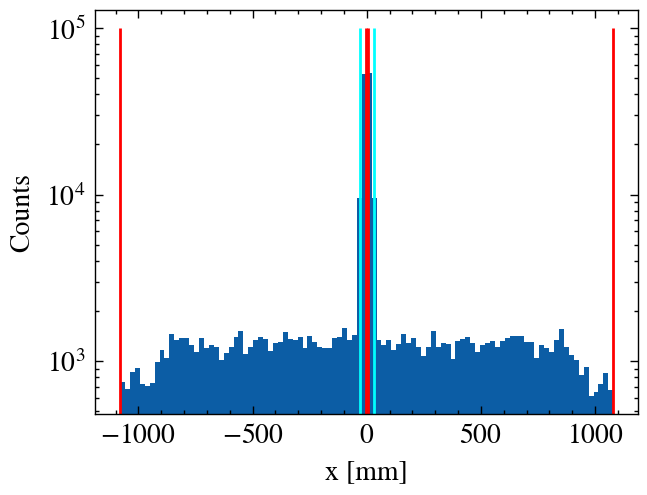

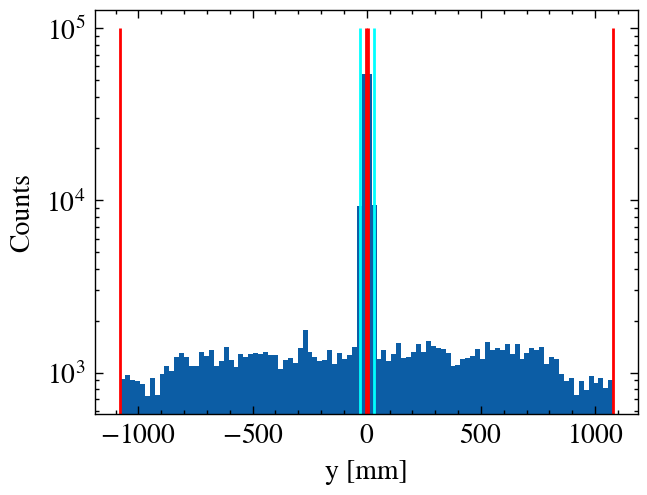

In [3]:
file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_Cracks_Gaussian"
Sim = SimFileReader(os.path.join(file_path, "sim_mu-_10000MeV_2160mm.root"))

branches = ["edep", "x_global", "y_global", "z_global", "x_local", "y_local", "z_local", "type"]
edeps, x_globals, y_globals, z_globals, x_locals, y_locals, z_locals, types = Sim.get_branches(branches)

#x and y local coordinates
with plt.style.context(['science', 'no-latex']):
    plt.rcParams['figure.dpi'] = 200
    plt.hist(ak.flatten(x_locals), bins = 100)
    plt.vlines(x=[-1080, 1080], ymin=0, ymax=100000, colors='red')
    plt.vlines(x=[-30, 30], ymin=0, ymax=100000, colors='cyan')
    plt.vlines(x=[-5, 5], ymin=0, ymax=100000, colors='red')
    plt.xlabel("x [mm]")
    plt.ylabel("Counts")
    plt.yscale("log")
    #plt.savefig(os.path.join(plotting_directory, "SplitCalGap_first_layer_energy.png"))
    plt.show()

with plt.style.context(['science', 'no-latex']):
    plt.rcParams['figure.dpi'] = 200
    plt.hist(ak.flatten(y_locals), bins = 100)
    plt.vlines(x=[-1080, 1080], ymin=0, ymax=100000, colors='red')
    plt.vlines(x=[-30, 30], ymin=0, ymax=100000, colors='cyan')
    plt.vlines(x=[-5, 5], ymin=0, ymax=100000, colors='red')
    plt.xlabel("y [mm]")
    plt.ylabel("Counts")
    plt.yscale("log")
    #plt.savefig(os.path.join(plotting_directory, "SplitCalGap_first_layer_energy.png"))
    plt.show()

## 3 mm Pb Hextant Centred

In [4]:
# MIP calibration

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_MIP_Calibration_Beam_Centred"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb_Centred_Beam"

Sim = SimFileReader(os.path.join(file_path, "sim_mu-_10000MeV_1000mm.root"))
MIP = MIP_Calibration(os.path.join(file_path, "sim_mu-_10000MeV_1000mm.root"), plotting_directory)

calibration_3mm_Pb_Centred = MIP.perform_fit()

print()
print(".........................................")
print("Printing Results of MIP calibration")
print(calibration_3mm_Pb_Centred)

Please wait, this program takes around 1 minute
to run its fits and output the plots

MIP_1cm
Initial peak = 2.3679 MeV
Fit range    = 1.00 - 75.57 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 62707.050

MPV            = 2.350007 MeV
MPV error      = 0.000790 MeV
Landau sigma   = 0.124056 MeV
Gaussian sigma = 0.327415 MeV
Amplitude      = 221236.664

MIP_6cm
Initial peak = 2.3563 MeV
Fit range    = 1.00 - 92.25 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 55722.343

MPV            = 2.363556 MeV
MPV error      = 0.000731 MeV
Landau sigma   = 0.125567 MeV
Gaussian sigma = 0.287103 MeV
Amplitude      = 213152.161

.........................................
Printing Results of MIP calibration
[[2.35000704e+00 7.90211413e-04]
 [2.36355614e+00 7.31245643e-04]]


Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb_Centred_Beam/MIP_1cm.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb_Centred_Beam/MIP_6cm.png has been created


Please wait, this program takes around 10 minutes
to run its fits and output the plots
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 92.065
ndof                = 97
chi2/ndof           = 0.949
Mean                = 120.897643 MIP
Mean error          = 0.087984 MIP
Sigma               = 8.323446 MIP
Sigma error         = 0.070138 MIP
Resolution sigma/mu = 0.068847
Resolution          = 6.885 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 76.500
ndof                = 97
chi2/ndof           = 0.789
Mean                = 363.773604 MIP
Mean error          = 0.153144 MIP
Sigma               = 14.541360 MIP
Sigma error         = 0.123289 MIP
Resolution sigma/mu = 0.039974
Resolution          = 3.997 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 76.226
ndof                = 97
chi2/ndof           = 0.786
Mean                = 606.970618 MIP
Mean error      

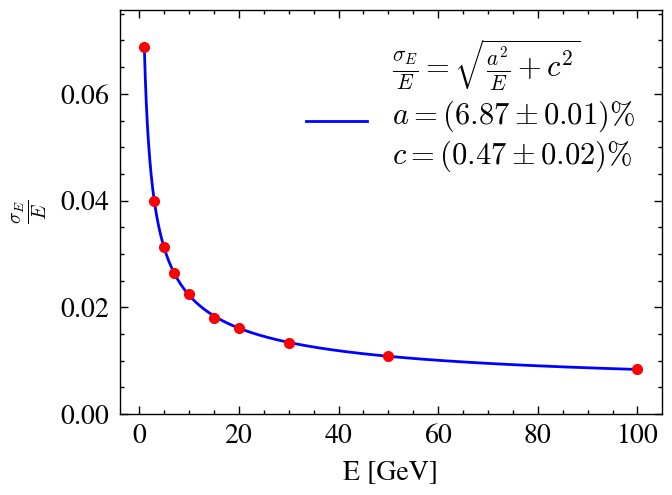

Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam/electron_response_1000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam/electron_response_3000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam/electron_response_5000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam/electron_response_7000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam/electron_response_10000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/EC

In [5]:
# ECAL Resolution

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_ECAL_Resolution_Beam_Centred"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb_Centred_Beam"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_3mm_Pb_Centred[:,0])

results = ECAL.perform_fit(energies, plotting_directory)

## 3 mm Pb Strip Centred

In [6]:
# MIP calibration

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_MIP_Calibration"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb"

Sim = SimFileReader(os.path.join(file_path, "sim_mu-_10000MeV_1000mm.root"))
MIP = MIP_Calibration(os.path.join(file_path, "sim_mu-_10000MeV_1000mm.root"), plotting_directory)

calibration_3mm_Pb = MIP.perform_fit()

print()
print(".........................................")
print("Printing Results of MIP calibration")
print(calibration_3mm_Pb)

Please wait, this program takes around 1 minute
to run its fits and output the plots

MIP_1cm
Initial peak = 2.3752 MeV
Fit range    = 1.00 - 91.97 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 60816.982

MPV            = 2.357221 MeV
MPV error      = 0.000775 MeV
Landau sigma   = 0.131528 MeV
Gaussian sigma = 0.310391 MeV
Amplitude      = 219026.228

MIP_6cm
Initial peak = 2.3650 MeV
Fit range    = 1.00 - 142.90 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 40093.806

MPV            = 2.381947 MeV
MPV error      = 0.000643 MeV
Landau sigma   = 0.143972 MeV
Gaussian sigma = 0.199071 MeV
Amplitude      = 204713.812

.........................................
Printing Results of MIP calibration
[[2.35722095e+00 7.74588425e-04]
 [2.38194694e+00 6.43138385e-04]]


Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb/MIP_1cm.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_3mm_Pb/MIP_6cm.png has been created


Please wait, this program takes around 10 minutes
to run its fits and output the plots
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 115.872
ndof                = 97
chi2/ndof           = 1.195
Mean                = 120.137451 MIP
Mean error          = 0.088864 MIP
Sigma               = 8.420246 MIP
Sigma error         = 0.070875 MIP
Resolution sigma/mu = 0.070088
Resolution          = 7.009 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 104.791
ndof                = 97
chi2/ndof           = 1.080
Mean                = 361.696488 MIP
Mean error          = 0.153191 MIP
Sigma               = 14.497183 MIP
Sigma error         = 0.127522 MIP
Resolution sigma/mu = 0.040081
Resolution          = 4.008 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 90.937
ndof                = 97
chi2/ndof           = 0.937
Mean                = 603.524347 MIP
Mean error    

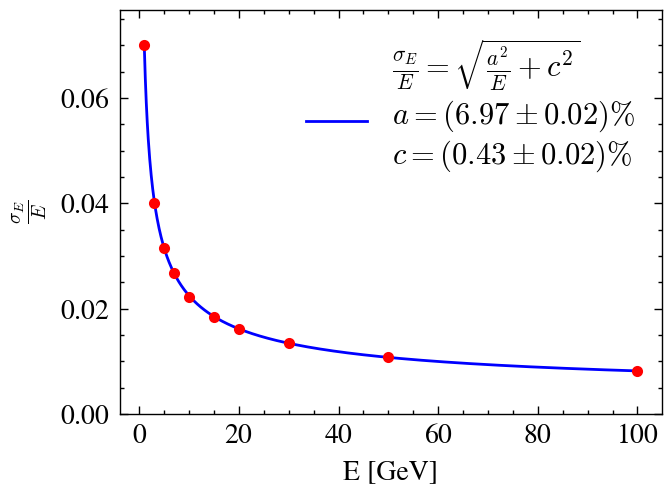

Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_1000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_3000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_5000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_7000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_10000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb/electron_response_15000MeV.png has been crea

In [7]:
# ECAL e- Resolution

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_ECAL_Resolution"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_3mm_Pb"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_3mm_Pb[:,0])

results = ECAL.perform_fit(energies, plotting_directory)

Please wait, this program takes around 10 minutes
to run its fits and output the plots
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 121.868
ndof                = 97
chi2/ndof           = 1.256
Mean                = 120.608003 MIP
Mean error          = 0.088101 MIP
Sigma               = 8.356034 MIP
Sigma error         = 0.068223 MIP
Resolution sigma/mu = 0.069283
Resolution          = 6.928 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 93.107
ndof                = 97
chi2/ndof           = 0.960
Mean                = 361.916984 MIP
Mean error          = 0.154274 MIP
Sigma               = 14.692888 MIP
Sigma error         = 0.123509 MIP
Resolution sigma/mu = 0.040597
Resolution          = 4.060 %
Running iminuit Gaussian minimisation...

iminuit valid       = True
chi2                = 112.181
ndof                = 97
chi2/ndof           = 1.157
Mean                = 604.120087 MIP
Mean error    

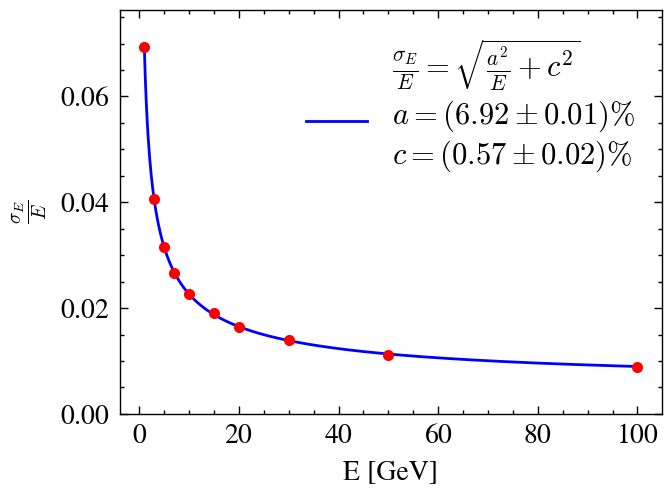

Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron_response_1000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron_response_3000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron_response_5000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron_response_7000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron_response_10000MeV.png has been created
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb/electron

In [8]:
# ECAL gamma Resolution

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_ECAL_Resolution_Gamma"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_3mm_Pb"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_3mm_Pb[:,0])

results = ECAL.perform_fit(energies, plotting_directory)

## 9 mm Fe Strip Centred


In [11]:
# MIP calibration (Vani's)

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/vmahajan/fe_mu_runs/sim_with10factor"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_9mm_Fe_VANI"

Sim = SimFileReader(os.path.join(file_path, "sim_mu-_10k_10000MeV.root"))
MIP = MIP_Calibration(os.path.join(file_path, "sim_mu-_10k_10000MeV.root"), plotting_directory)


calibration_9mm_Fe_VANI = MIP.perform_fit()

print()
print(".........................................")
print("Printing Results of MIP calibration")
print(calibration_9mm_Fe_VANI)

Please wait, this program takes around 1 minute
to run its fits and output the plots

MIP_1cm
Initial peak = 2.2718 MeV
Fit range    = 1.00 - 29.28 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 383.565

MPV            = 1.800000 MeV
MPV error      = 0.012402 MeV
Landau sigma   = 0.269665 MeV
Gaussian sigma = 0.886917 MeV
Amplitude      = 3944.078

MIP_6cm
Initial peak = 2.2619 MeV
Fit range    = 1.00 - 34.18 MeV

Running iminuit minimisation...

iminuit valid = True
NLL/deviance   = 387.553

MPV            = 1.948662 MeV
MPV error      = 0.029837 MeV
Landau sigma   = 0.370618 MeV
Gaussian sigma = 0.709682 MeV
Amplitude      = 2396.489

.........................................
Printing Results of MIP calibration
[[1.80000002 0.01240225]
 [1.94866177 0.02983701]]


Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_9mm_Fe_VANI/MIP_1cm.png has been created
Warning in <TROOT::Append>: Replacing existing TH1: MIP_6cm (Potential memory leak).
Info in <TCanvas::Print>: png file /afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_9mm_Fe_VANI/MIP_6cm.png has been created


In [ ]:
# ECAL Resolution (Vani's)

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/vmahajan/fe_e-_runs/sim_with10factor"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_9mm_Fe_VANI"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_9mm_Fe_VANI[:,0])

results = ECAL.perform_fit(energies, plotting_directory)

In [ ]:
# MIP calibration (Elliott's)

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_MIP_Calibration_9mm_Fe"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/run_MIP_Calibration_9mm_Fe"

Sim = SimFileReader(os.path.join(file_path, "sim_mu-_10k_10000MeV.root"))
MIP = MIP_Calibration(os.path.join(file_path, "sim_mu-_10k_10000MeV.root"), plotting_directory)


calibration_9mm_Fe = MIP.perform_fit()

print()
print(".........................................")
print("Printing Results of MIP calibration")
print(calibration_9mm_Fe)

In [ ]:
# ECAL e- Resolution (Elliott's)

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_ECAL_Resolution_9mm_Fe"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_9mm_Fe"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_9mm_Fe[:,0])

results = ECAL.perform_fit(energies, plotting_directory)

In [ ]:
# ECAL gamma Resolution (Elliott's)

energies = np.array([1_000, 3_000, 5_000, 7_000, 10_000, 15_000, 20_000, 30_000, 50_000, 100_000])

file_path =  r"/eos/experiment/ship/user/Mainz_Sim_Data/ewrightl/sim_runs/run_ECAL_Resolution_Gamma_9mm_Fe"
plotting_directory = r"/afs/cern.ch/user/e/elwright/ECAL_Simulation_Analysis/Figures/ECAL_Resolution_Gamma_9mm_Fe"

ECAL = ECAL_Resolution(file_path, plotting_directory, calibration_9mm_Fe[:,0])

results = ECAL.perform_fit(energies, plotting_directory)